In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings 
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score
import shap

In [2]:
sns.set(style="whitegrid")
plt.rcParams['figure.figsize'] = (8, 5)

In [3]:
df = pd.read_csv("solardataset.csv")
df.head()

,Cell_stack_sequence,Cell_architecture,Substrate_stack_sequence,ETL_stack_sequence,ETL_deposition_procedure,Perovskite_composition_a_ions,Perovskite_composition_b_ions,Perovskite_composition_c_ions,Perovskite_composition_short_form,Perovskite_additives_compounds,...,Backcontact_stack_sequence,Backcontact_thickness_list,Backcontact_deposition_procedure,Encapsulation,Encapsulation_stack_sequence,JV_measured,JV_default_Voc,JV_default_Jsc,JV_default_FF,JV_default_PCE
0,SLG | FTO | TiO2-c | TiO2-mp | Perovskite | Sp...,nip,SLG | FTO,TiO2-c | TiO2-mp,Spray-pyrolys | Spin-coating,Cs,Sn,I,CsSnI,NaN,...,Au,90.0,Evaporation,False,Unknown,True,0.002,0.22,0.57,0.00
1,SLG | FTO | TiO2-c | TiO2-mp | Perovskite | Sp...,nip,SLG | FTO,TiO2-c | TiO2-mp,Spray-pyrolys | Spin-coating,Cs,Sn,Br; I,CsSnBrI,NaN,...,Au,90.0,Evaporation,False,Unknown,True,0.120,0.49,0.25,0.00
2,SLG | FTO | TiO2-c | TiO2-mp | Perovskite | Sp...,nip,SLG | FTO,TiO2-c | TiO2-mp,Spray-pyrolys | Spin-coating,Cs,Sn,Br; I,CsSnBrI,NaN,...,Au,90.0,Evaporation,False,Unknown,True,0.135,3.69,0.26,0.13
3,SLG | FTO | TiO2-c | TiO2-mp | Perovskite | Sp...,nip,SLG | FTO,TiO2-c | TiO2-mp,Spray-pyrolys | Spin-coating,Cs,Sn,Br; I,CsSnBrI,NaN,...,Au,90.0,Evaporation,False,Unknown,True,0.227,1.32,0.41,0.12
4,SLG | FTO | TiO2-c | TiO2-mp | Perovskite | Sp...,nip,SLG | FTO,TiO2-c | TiO2-mp,Spray-pyrolys | Spin-coating,Cs,Sn,Br,CsSnBr,NaN,...,Au,90.0,Evaporation,False,Unknown,True,0.190,1.57,0.34,0.10


In [4]:
df.shape
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42443 entries, 0 to 42442
Data columns (total 30 columns):
 #   Column                                                   Non-Null Count  Dtype  
---  ------                                                   --------------  -----  
 0   Cell_stack_sequence                                      42443 non-null  object 
 1   Cell_architecture                                        42443 non-null  object 
 2   Substrate_stack_sequence                                 42443 non-null  object 
 3   ETL_stack_sequence                                       42443 non-null  object 
 4   ETL_deposition_procedure                                 42443 non-null  object 
 5   Perovskite_composition_a_ions                            42414 non-null  object 
 6   Perovskite_composition_b_ions                            42438 non-null  object 
 7   Perovskite_composition_c_ions                            42438 non-null  object 
 8   Perovskite_composition_sho

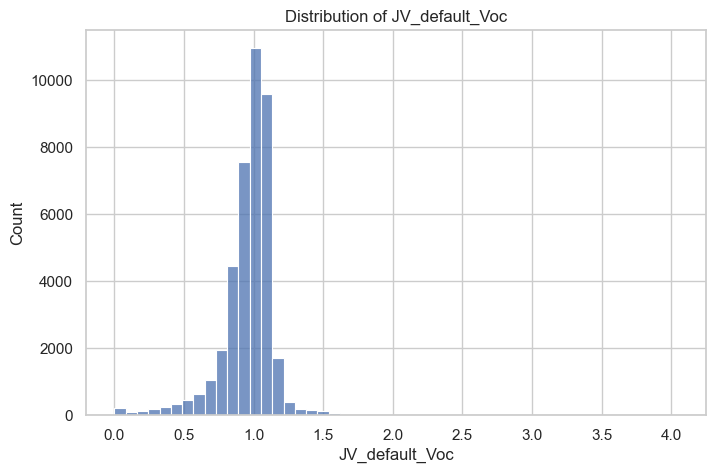

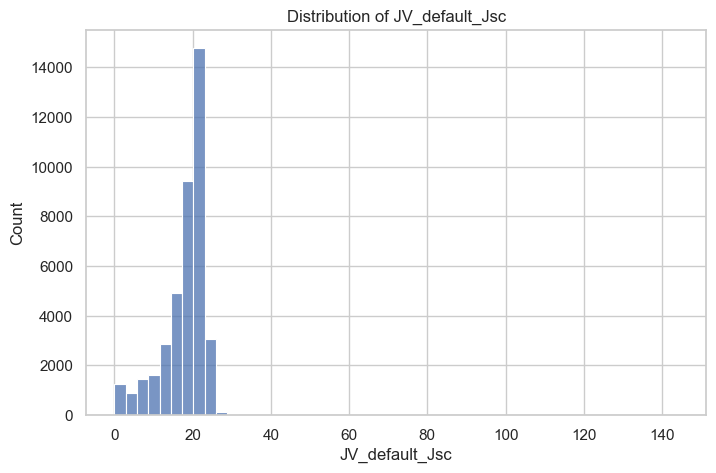

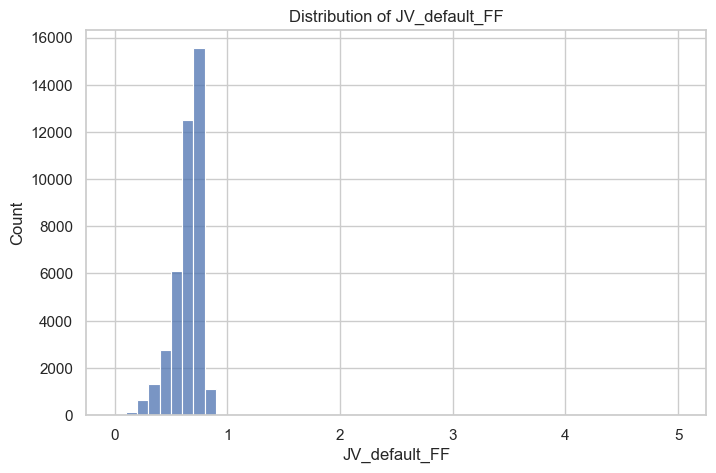

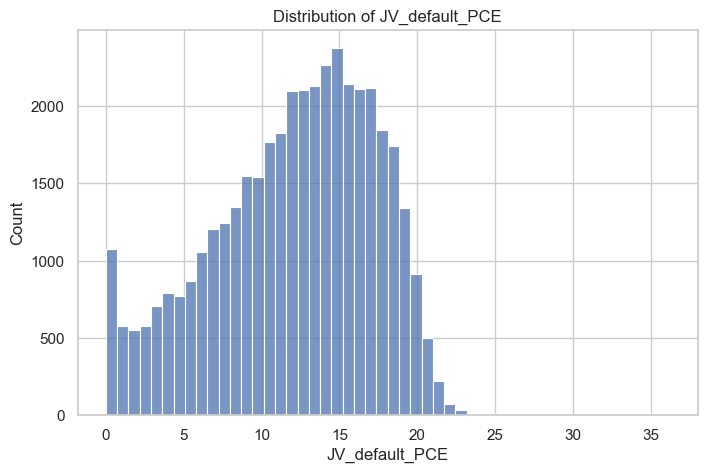

In [5]:
cols = ['JV_default_Voc', 'JV_default_Jsc', 'JV_default_FF', 'JV_default_PCE']

for col in cols:
    plt.figure()
    sns.histplot(df[col], bins=50)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.show()

In [6]:
df = df.drop([
    'Perovskite_additives_concentrations',
    'Perovskite_additives_compounds',
    'Perovskite_thickness',
    'Backcontact_thickness_list'
], axis=1)

In [7]:
df = df.dropna(subset=['JV_default_PCE'])

In [8]:
df = df.dropna(subset=[
    'JV_default_Voc',
    'JV_default_Jsc',
    'JV_default_FF'
])

In [9]:
df['Perovskite_composition_a_ions'] = df['Perovskite_composition_a_ions'].fillna('Unknown')
df['Perovskite_composition_b_ions'] = df['Perovskite_composition_b_ions'].fillna('Unknown')
df['Perovskite_composition_c_ions'] = df['Perovskite_composition_c_ions'].fillna('Unknown')

In [10]:
df['Perovskite_deposition_thermal_annealing_temperature'] = pd.to_numeric(
    df['Perovskite_deposition_thermal_annealing_temperature'], errors='coerce'
)

df['Perovskite_deposition_thermal_annealing_time'] = pd.to_numeric(
    df['Perovskite_deposition_thermal_annealing_time'], errors='coerce'
)

In [11]:
df.isnull().sum().sort_values(ascending=False)

Perovskite_deposition_thermal_annealing_time               17010
Perovskite_deposition_thermal_annealing_temperature        16386
Substrate_stack_sequence                                       0
ETL_stack_sequence                                             0
ETL_deposition_procedure                                       0
Perovskite_composition_a_ions                                  0
Perovskite_composition_b_ions                                  0
Perovskite_composition_c_ions                                  0
Cell_stack_sequence                                            0
Cell_architecture                                              0
Perovskite_deposition_number_of_deposition_steps               0
Perovskite_composition_short_form                              0
Perovskite_deposition_solvents                                 0
Perovskite_deposition_procedure                                0
Perovskite_deposition_quenching_induced_crystallisation        0
HTL_stack_sequence       

In [12]:
df['Perovskite_deposition_thermal_annealing_temperature'].fillna(
    df['Perovskite_deposition_thermal_annealing_temperature'].median(),
    inplace=True
)

df['Perovskite_deposition_thermal_annealing_time'].fillna(
    df['Perovskite_deposition_thermal_annealing_time'].median(),
    inplace=True
)
df.isnull().sum().sum()

np.int64(0)

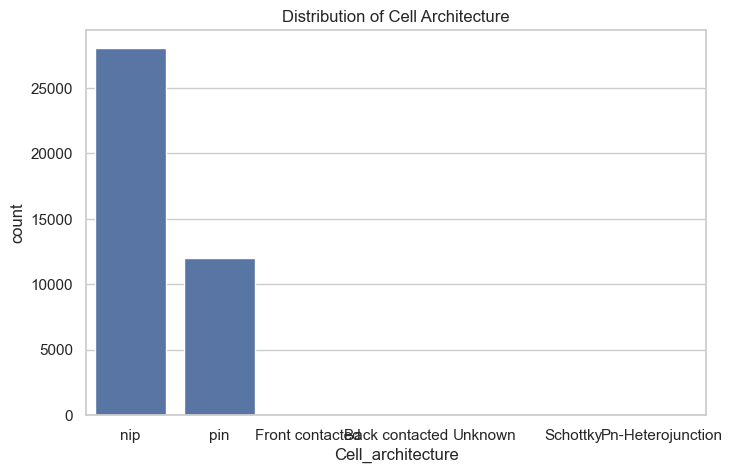

In [13]:
df['Cell_architecture'].value_counts()
sns.countplot(x='Cell_architecture', data=df)
plt.title("Distribution of Cell Architecture")
plt.show()

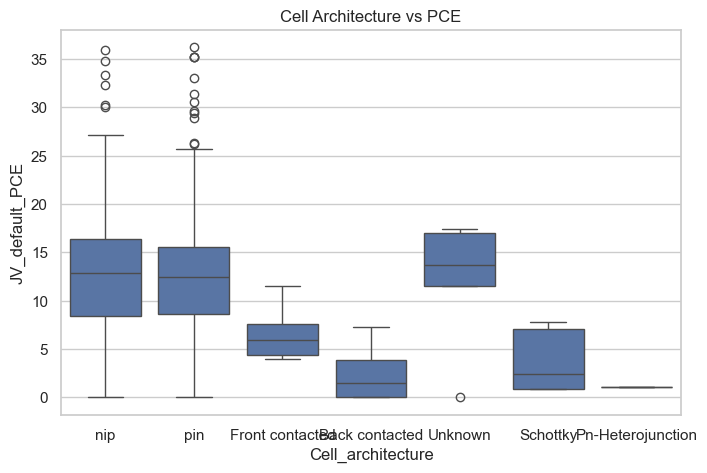

In [14]:
sns.boxplot(x='Cell_architecture', y='JV_default_PCE', data=df)
plt.title("Cell Architecture vs PCE")
plt.show()

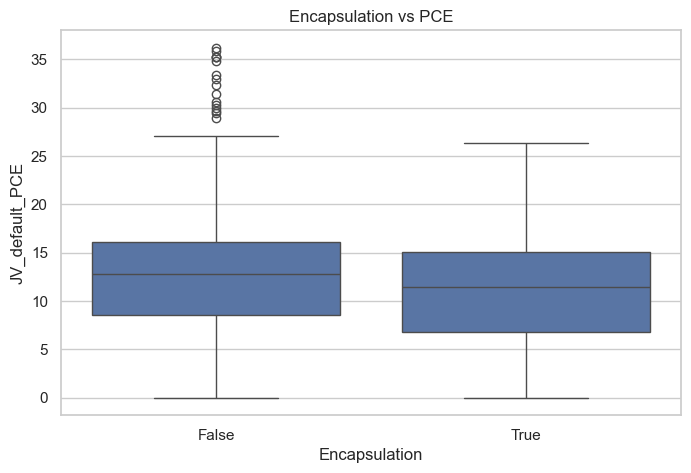

In [15]:
sns.boxplot(x='Encapsulation', y='JV_default_PCE', data=df)
plt.title("Encapsulation vs PCE")
plt.show()

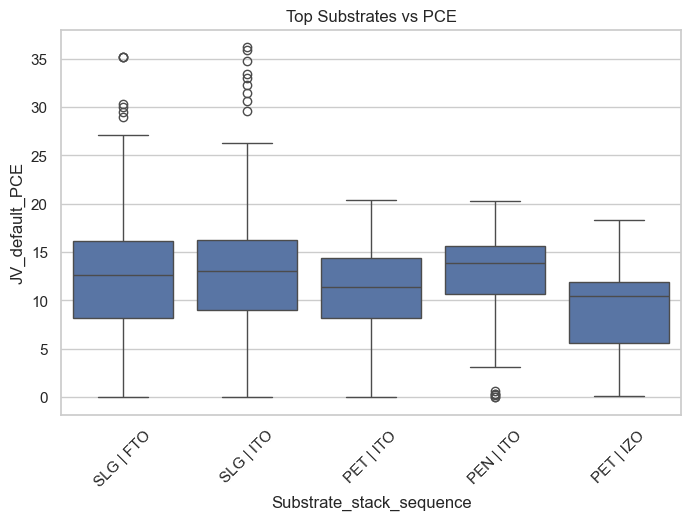

In [16]:
top_sub = df['Substrate_stack_sequence'].value_counts().head(5).index

sns.boxplot(
    x='Substrate_stack_sequence',
    y='JV_default_PCE',
    data=df[df['Substrate_stack_sequence'].isin(top_sub)]
)

plt.xticks(rotation=45)
plt.title("Top Substrates vs PCE")
plt.show()

In [17]:
df['ETL_stack_sequence'].value_counts().head(10)

ETL_stack_sequence
TiO2-c | TiO2-mp              11068
TiO2-c                         6472
PCBM-60                        3056
PCBM-60 | BCP                  2522
SnO2-np                        1558
C60 | BCP                      1420
SnO2-c                         1297
TiO2-c | TiO2-mp | ZrO2-mp      614
ZnO-c                           462
PCBM-60 | C60 | BCP             420
Name: count, dtype: int64

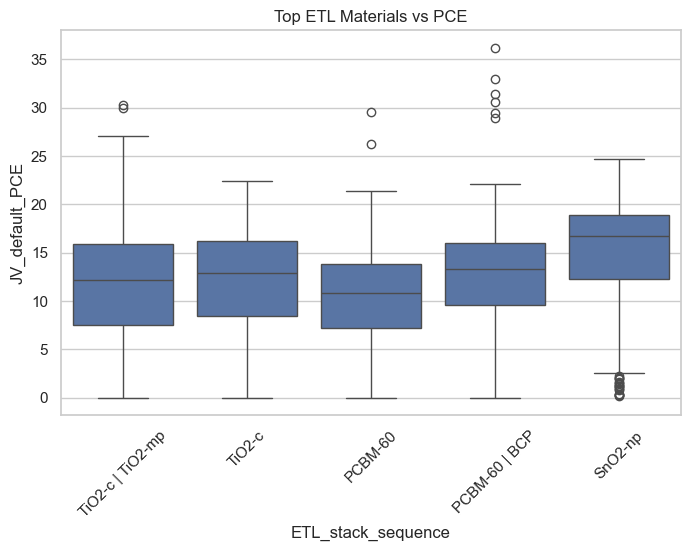

In [18]:
top_etl = df['ETL_stack_sequence'].value_counts().head(5).index

sns.boxplot(
    x='ETL_stack_sequence',
    y='JV_default_PCE',
    data=df[df['ETL_stack_sequence'].isin(top_etl)]
)

plt.xticks(rotation=45)
plt.title("Top ETL Materials vs PCE")
plt.show()

In [19]:
df['Perovskite_composition_short_form'].value_counts().head(10)

Perovskite_composition_short_form
MAPbI          25568
CsFAMAPbBrI     3376
FAMAPbBrI       2702
FAMAPbI          873
CsPbBrI          854
MAPbBrI          597
CsFAPbBrI        554
FAPbI            535
CsPbBr           426
CsPbI            421
Name: count, dtype: int64

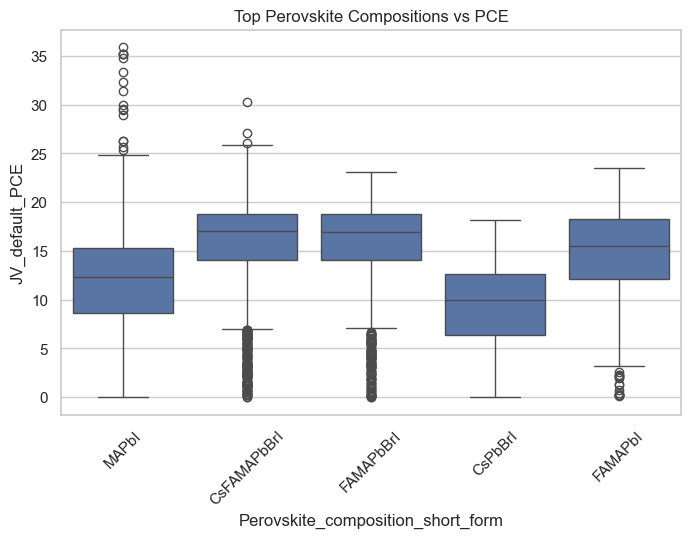

In [20]:
top_comp = df['Perovskite_composition_short_form'].value_counts().head(5).index

sns.boxplot(
    x='Perovskite_composition_short_form',
    y='JV_default_PCE',
    data=df[df['Perovskite_composition_short_form'].isin(top_comp)]
)

plt.xticks(rotation=45)
plt.title("Top Perovskite Compositions vs PCE")
plt.show()

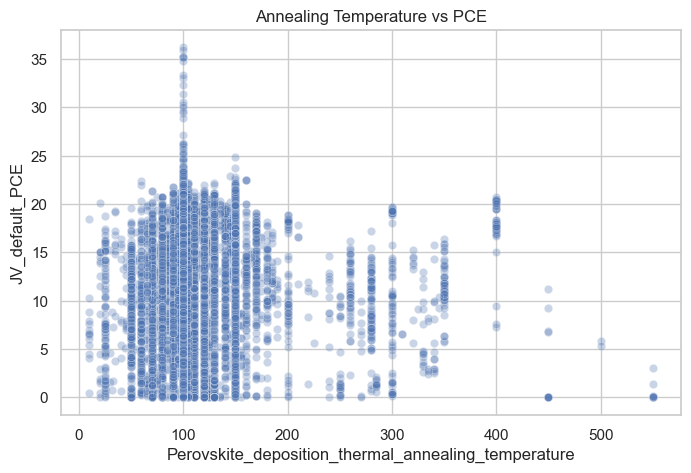

In [21]:
sns.scatterplot(
    x='Perovskite_deposition_thermal_annealing_temperature',
    y='JV_default_PCE',
    data=df,
    alpha=0.3
)

plt.title("Annealing Temperature vs PCE")
plt.show()

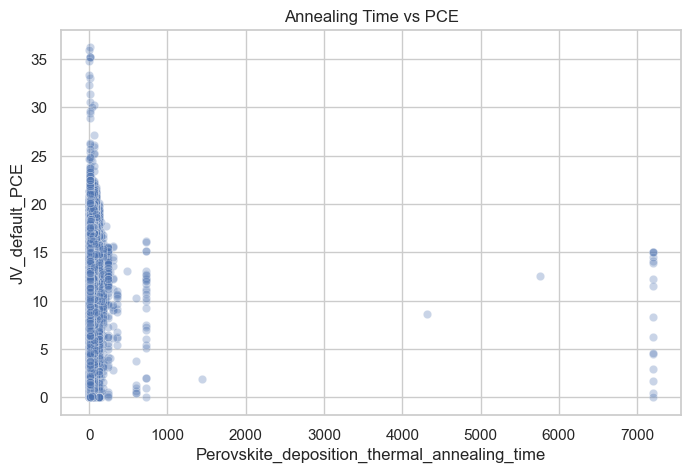

In [22]:
sns.scatterplot(
    x='Perovskite_deposition_thermal_annealing_time',
    y='JV_default_PCE',
    data=df,
    alpha=0.3
)

plt.title("Annealing Time vs PCE")
plt.show()

In [23]:
df['HTL_stack_sequence'].value_counts().head(10)

HTL_stack_sequence
Spiro-MeOTAD    19776
PEDOT:PSS        6145
none             2511
PTAA             1720
NiO-c            1589
P3HT              832
NiO-np            375
CuSCN             213
NiMgLiO           152
NiO               148
Name: count, dtype: int64

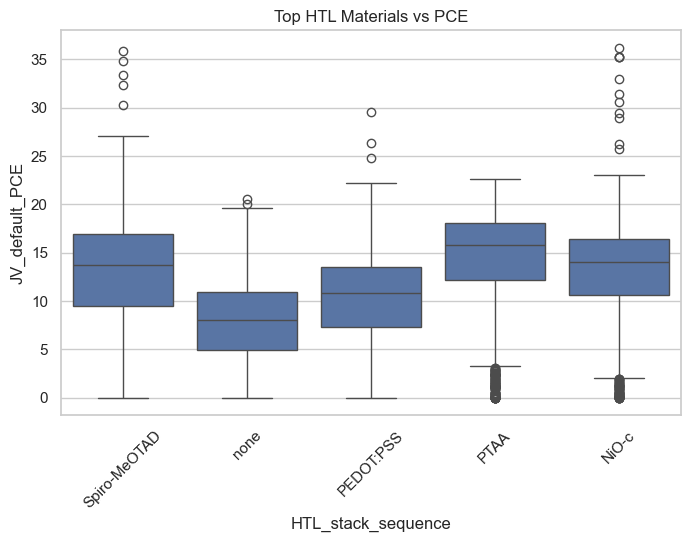

In [24]:
top_htl = df['HTL_stack_sequence'].value_counts().head(5).index

sns.boxplot(
    x='HTL_stack_sequence',
    y='JV_default_PCE',
    data=df[df['HTL_stack_sequence'].isin(top_htl)]
)

plt.xticks(rotation=45)
plt.title("Top HTL Materials vs PCE")
plt.show()

In [25]:
df['Backcontact_stack_sequence'].value_counts().head(10)

Backcontact_stack_sequence
Au           19328
Ag           12322
Al            2943
Carbon        2031
MoO3 | Ag      614
Cu             485
Ca | Al        288
MoO3 | Al      115
MoO3 | Au      114
AgAl            77
Name: count, dtype: int64

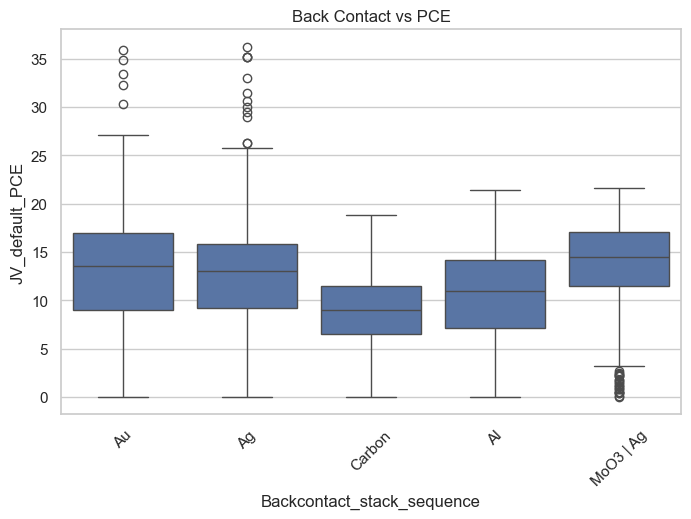

In [26]:
top_bc = df['Backcontact_stack_sequence'].value_counts().head(5).index

sns.boxplot(
    x='Backcontact_stack_sequence',
    y='JV_default_PCE',
    data=df[df['Backcontact_stack_sequence'].isin(top_bc)]
)

plt.xticks(rotation=45)
plt.title("Back Contact vs PCE")
plt.show()

In [27]:
[col for col in df_encoded.columns if 'JV' in col]

NameError: name 'df_encoded' is not defined

In [ ]:
def reduce_categories(col, top_n=5):
    top_categories = df[col].value_counts().nlargest(top_n).index
    df[col] = df[col].apply(lambda x: x if x in top_categories else 'Other')

high_card_cols = [
    'ETL_stack_sequence',
    'HTL_stack_sequence',
    'Backcontact_stack_sequence'
]

for col in high_card_cols:
    reduce_categories(col, top_n=5)

In [ ]:
df = df.drop([
    'JV_default_Voc',
    'JV_default_Jsc',
    'JV_default_FF'
], axis=1)

In [ ]:
df_encoded = pd.get_dummies(df, drop_first=True)

In [ ]:
df_encoded.shape

(40073, 7674)

In [ ]:
[col for col in df_encoded.columns if 'JV' in col]

['JV_measured', 'JV_default_PCE']

In [ ]:
X = df_encoded.drop('JV_default_PCE', axis=1)
y = df_encoded['JV_default_PCE']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [ ]:
model = RandomForestRegressor(
    n_estimators=30,      # ↓ reduce trees (100 → 30)
    max_depth=10,         # limit tree depth
    n_jobs=-1,            # use all CPU cores
    random_state=42
)
model.fit(X_train, y_train)

,n_estimators,30
,criterion,'squared_error'
,max_depth,10
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [ ]:
y_pred = model.predict(X_test)

In [ ]:
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("RMSE:", rmse)
print("R2 Score:", r2)

RMSE: 4.092802145765507
R2 Score: 0.39079011652084794


In [ ]:
importances = model.feature_importances_
feature_names = X.columns

feat_imp = pd.Series(importances, index=feature_names)
feat_imp = feat_imp.sort_values(ascending=False)

feat_imp.head(20)

Perovskite_deposition_quenching_induced_crystallisation    0.286799
Perovskite_composition_b_ions_Pb                           0.086000
Perovskite_composition_c_ions_Br                           0.058402
Perovskite_composition_a_ions_FA; MA                       0.051326
Perovskite_composition_b_ions_Sn                           0.048185
HTL_stack_sequence_PEDOT:PSS                               0.047511
Perovskite_composition_c_ions_Br; I                        0.042155
Perovskite_deposition_solvents_DMF; DMSO >> IPA            0.042125
HTL_stack_sequence_none                                    0.024011
HTL_deposition_procedure_Unknown                           0.023717
Perovskite_deposition_solvents_GBL                         0.017856
HTL_stack_sequence_PTAA                                    0.017624
Perovskite_composition_a_ions_Cs                           0.016203
Perovskite_composition_b_ions_Bi                           0.012954
Perovskite_deposition_solvents_DMF              

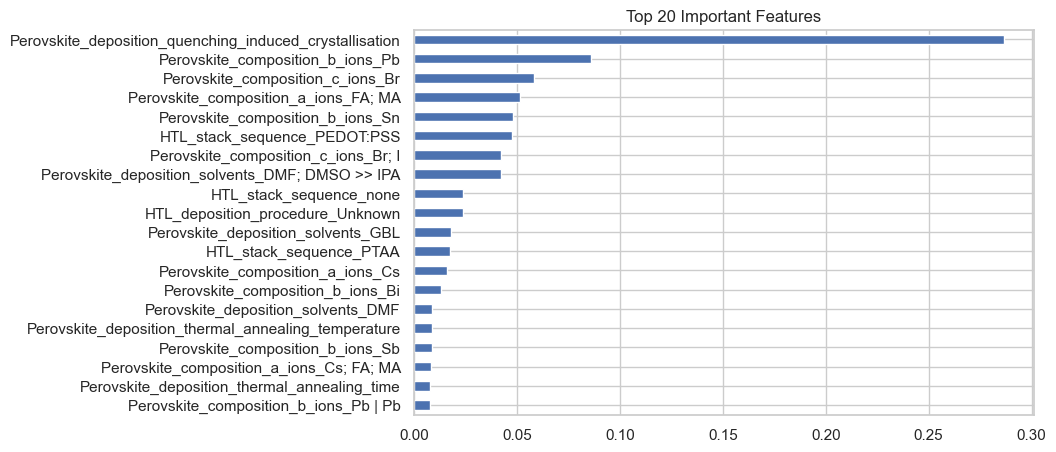

In [ ]:
feat_imp.head(20).plot(kind='barh')
plt.title("Top 20 Important Features")
plt.gca().invert_yaxis()
plt.show()

In [ ]:
top_features = feat_imp.head(100).index

X_reduced = X[top_features]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X_reduced, y, test_size=0.2, random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("RMSE:", rmse)
print("R2 Score:", r2)

RMSE: 4.097781451331768
R2 Score: 0.3893068845934241


In [ ]:
elements = ['Cs', 'FA', 'MA', 'Pb', 'Sn', 'Br', 'I']

for el in elements:
    df[el] = df['Perovskite_composition_short_form'].apply(lambda x: 1 if el in x else 0)

In [ ]:
df = df.drop('Perovskite_composition_short_form', axis=1)

In [ ]:
df_encoded = pd.get_dummies(df, drop_first=True)

In [ ]:
X = df_encoded.drop('JV_default_PCE', axis=1)
y = df_encoded['JV_default_PCE']

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [ ]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=20,
    max_depth=8,
    n_jobs=-1,
    random_state=42
)

model.fit(X_train, y_train)

,n_estimators,20
,criterion,'squared_error'
,max_depth,8
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [ ]:

importances = model.feature_importances_
feat_imp = pd.Series(importances, index=X.columns)
feat_imp = feat_imp.sort_values(ascending=False)

In [ ]:
top_features = feat_imp.head(100).index

X_reduced = X[top_features]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X_reduced, y, test_size=0.2, random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("RMSE:", rmse)
print("R2 Score:", r2)

RMSE: 4.133765915229174
R2 Score: 0.3785342492787991


In [ ]:
kmeans = KMeans(n_clusters=5, random_state=42)
clusters = kmeans.fit_predict(X_reduced)

df['cluster'] = clusters

In [ ]:
df.groupby('cluster')['JV_default_PCE'].mean()

cluster
0    11.805715
1     8.961667
2    10.355686
3     9.985675
4    13.430176
Name: JV_default_PCE, dtype: float64

In [ ]:
#plot
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_reduced)

kmeans = KMeans(n_clusters=5, random_state=42)

clusters = kmeans.fit_predict(X_reduced)

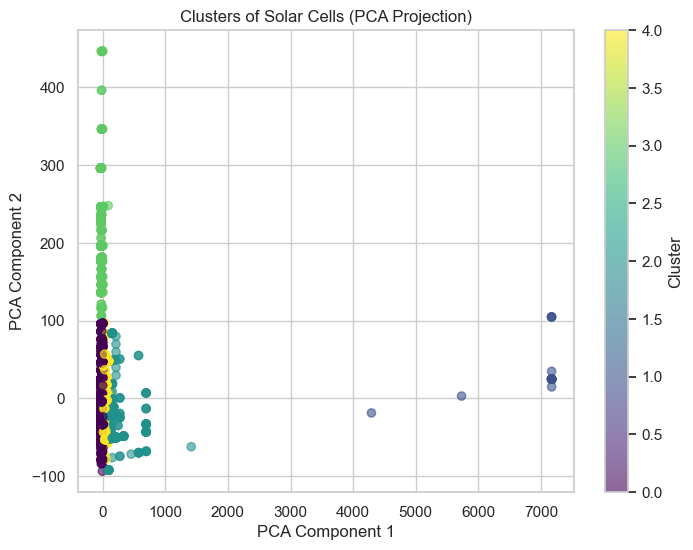

In [ ]:
plt.figure(figsize=(8,6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=clusters,
    cmap='viridis',
    alpha=0.6
)

plt.title("Clusters of Solar Cells (PCA Projection)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.colorbar(label="Cluster")
plt.show()

In [ ]:
df['cluster'] = clusters
df.groupby('cluster')['JV_default_PCE'].mean()

cluster
0    11.805715
1     8.961667
2    10.355686
3     9.985675
4    13.430176
Name: JV_default_PCE, dtype: float64

In [ ]:
df.groupby('cluster').mean(numeric_only=True)

,Perovskite_deposition_number_of_deposition_steps,Perovskite_deposition_quenching_induced_crystallisation,Perovskite_deposition_thermal_annealing_temperature,Perovskite_deposition_thermal_annealing_time,Encapsulation,JV_measured,JV_default_PCE,Cs,FA,MA,Pb,Sn,Br,I
cluster,,,,,,,,,,,,,,
0,1.347647,0.443579,101.865688,14.388589,0.037852,0.999969,11.805715,0.135522,0.189631,0.884428,0.971270,0.033415,0.180354,0.974155
1,1.000000,0.055556,33.333333,6960.000000,0.000000,1.000000,8.961667,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,1.000000
2,0.994872,0.085897,83.294872,177.455128,0.020513,1.000000,10.355686,0.053846,0.058974,0.952564,0.985897,0.007692,0.061538,0.998718
3,1.111111,0.387707,313.274232,8.946054,0.106383,1.000000,9.985675,0.784870,0.172577,0.182033,0.867612,0.004728,0.751773,0.829787
4,1.010270,0.669989,100.592358,60.093641,0.040024,1.000000,13.430176,0.347833,0.522882,0.942305,0.992448,0.005135,0.520314,0.985048


In [ ]:
df.groupby('cluster')['Perovskite_composition_a_ions'].value_counts().head(10)


cluster  ETL_stack_sequence
0        Other                 12492
         TiO2-c | TiO2-mp       8324
         TiO2-c                 5110
         PCBM-60                2696
         PCBM-60 | BCP          2335
         SnO2-np                1274
1        Other                    18
2        Other                   491
         TiO2-c                  115
         PCBM-60                  73
Name: count, dtype: int64

In [ ]:
df.groupby('cluster')['ETL_stack_sequence'].value_counts().head(10)

cluster  ETL_stack_sequence
0        Other                 12492
         TiO2-c | TiO2-mp       8324
         TiO2-c                 5110
         PCBM-60                2696
         PCBM-60 | BCP          2335
         SnO2-np                1274
1        Other                    18
2        Other                   491
         TiO2-c                  115
         PCBM-60                  73
Name: count, dtype: int64

In [ ]:
from sklearn.ensemble import IsolationForest

iso = IsolationForest(
    n_estimators=100,
    contamination=0.02,   # assume ~2% anomalies
    random_state=42
)

anomaly_labels = iso.fit_predict(X_reduced)

In [ ]:
df['anomaly'] = anomaly_labels
df['anomaly'].value_counts()

anomaly
 1    39271
-1      802
Name: count, dtype: int64

In [ ]:
df.groupby('anomaly')['JV_default_PCE'].mean()

anomaly
-1     7.734539
 1    12.113030
Name: JV_default_PCE, dtype: float64

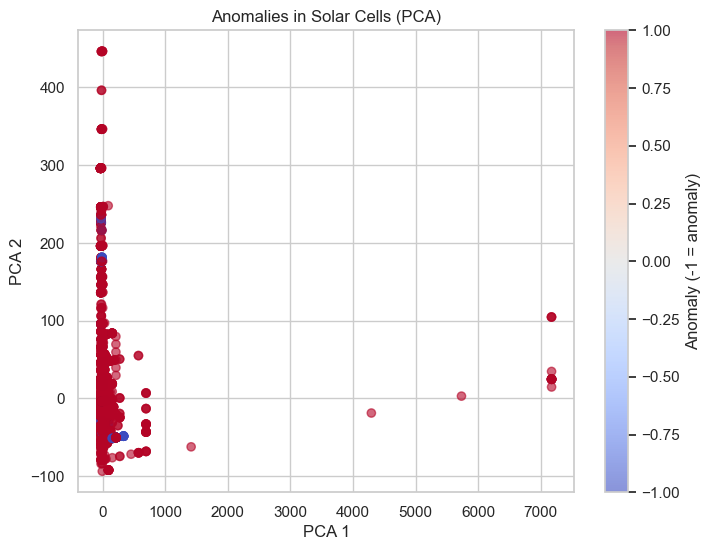

In [ ]:
plt.figure(figsize=(8,6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=df['anomaly'],
    cmap='coolwarm',
    alpha=0.6
)

plt.title("Anomalies in Solar Cells (PCA)")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.colorbar(label="Anomaly (-1 = anomaly)")
plt.show()

In [ ]:
anomalies = df[df['anomaly'] == -1]

anomalies[['JV_default_PCE', 'Cs', 'FA', 'MA', 'Pb', 'Br', 'I']].head(10)

,JV_default_PCE,Cs,FA,MA,Pb,Br,I
75,1.60,1,0,0,0,1,1
76,2.02,1,0,0,0,1,1
77,1.08,1,0,0,0,1,1
78,0.00,1,0,0,0,1,1
429,7.10,0,1,0,0,0,1
436,8.30,0,1,0,0,0,1
636,5.26,1,0,0,1,1,0
637,7.87,1,0,0,1,1,0
690,6.16,1,0,0,1,1,0
691,5.69,1,0,0,1,1,0


In [ ]:
X_train = X_train.astype(float)
X_test = X_test.astype(float)

In [ ]:
explainer = shap.TreeExplainer(model)

In [ ]:
X_sample = X_test.sample(300, random_state=42)

In [ ]:
shap_values = explainer.shap_values(X_sample)

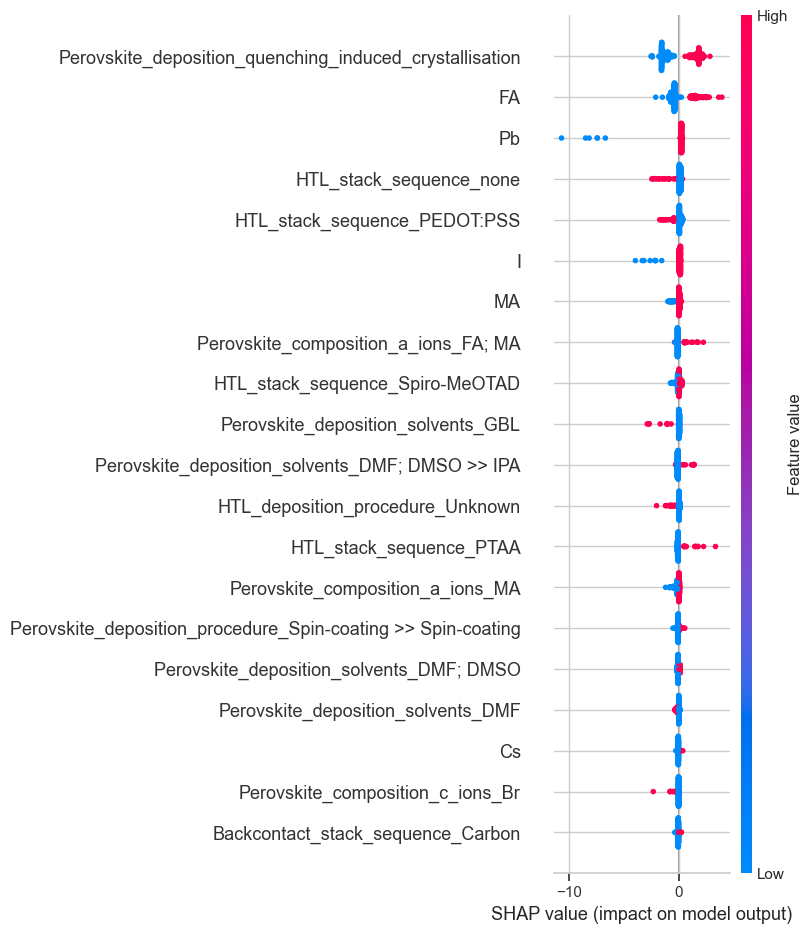

In [ ]:
shap.summary_plot(shap_values, X_sample)

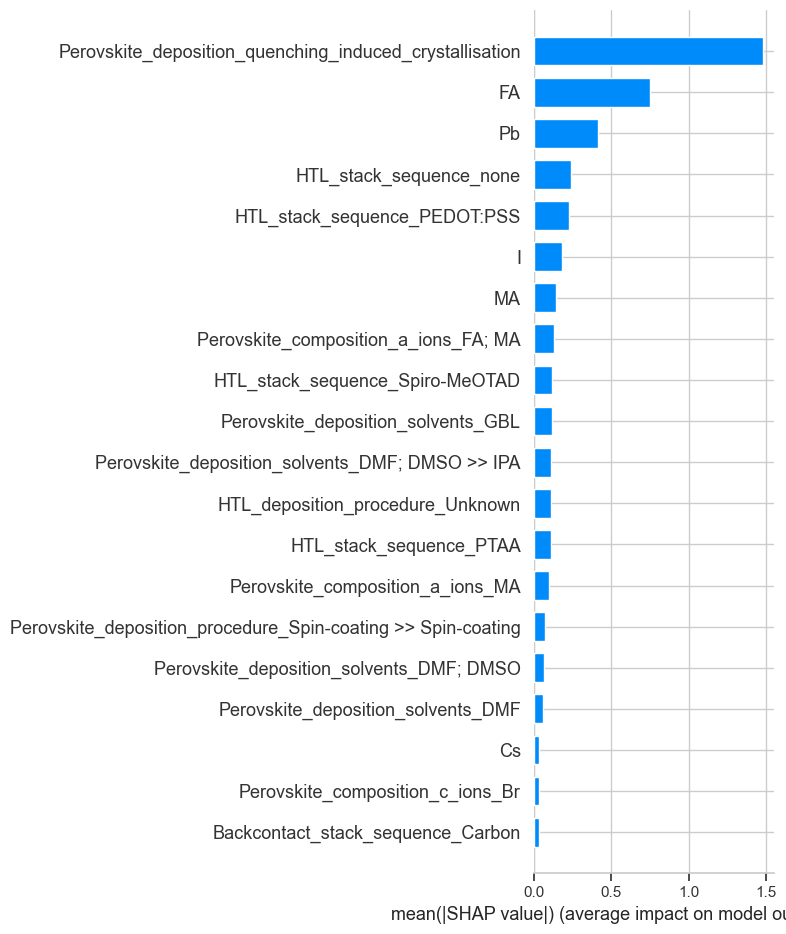

In [ ]:
shap.summary_plot(shap_values, X_sample, plot_type="bar")